# Telegram Mention Network Analysis: Pro-Kremlin vs Anti-Kremlin Channels

This notebook examines the topological structure of political Telegram channel mentions during the initial phase of the Russia–Ukraine conflict (Feb 24 – May 24, 2022), using data from Bawa et al. (2025).

**Important information:**
- Nodes: Telegram channels (pro-kremlin, anti-kremlin);
- Edges: a mention from one channel to another;
- Edge weights: number of mentions;
- Study period: 24 February – 24 May 2022;
- Data: public Telegram channels. Source: Bawa et al. (2025), [arXiv:2501.01884.](https://doi.org/10.1609/icwsm.v19i1.35939)

### 1. Setup 

* Here we initialise the environment and set up directory structures.

In [2]:
import os
import pickle
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm import tqdm

SEED = 42
rng = np.random.default_rng(SEED)

BASE_DIR = Path(".")
ANTI_DIR = BASE_DIR / "anti_kremlin_dataset"
PRO_DIR = BASE_DIR / "pro_kremlin_dataset"
ANTI_LIST = BASE_DIR / "anti_kremlin_channel_list.csv"
PRO_LIST = BASE_DIR / "pro_kremlin_channels_list.csv"

OUT_DIR = BASE_DIR / "outputs"
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

START = pd.Timestamp("2022-02-24", tz="UTC")
END = pd.Timestamp("2022-05-25", tz="UTC")  # exclusive, so 24 May is included

CHUNK_SIZE = 50_000

for p in [ANTI_DIR, PRO_DIR, ANTI_LIST, PRO_LIST]:
    if not p.exists():
        raise FileNotFoundError(f"Missing: {p.resolve()}")

print("Setup complete.")

Setup complete.


### 2. Data preparation

* Here we standardize identificators, parse two lists and validate group integrity.

In [3]:
#categorical columns for classification
CLASS_COLS = ["pro_kremlin", "anti_kremlin", "neutral", "others"]

#cleaning function for usernames
def clean_username(value):
    if pd.isna(value):
        return ""
    return str(value).strip().lower().lstrip("@")

#cleaning function for channels
def clean_channels(df, group):
    df = df.copy()
    df["username"] = df["username"].map(clean_username)
    df = df[df["username"] != ""]

    cols = [c for c in CLASS_COLS if c in df.columns]
    df["_filled"] = df[cols].notna().sum(axis=1) if cols else 0
    df = (
        df.sort_values("_filled", ascending=False)
          .drop_duplicates("username")
          .drop(columns="_filled")
    )

    if "channel_name" not in df.columns:
        df["channel_name"] = df["username"]
    df["channel_name"] = df["channel_name"].fillna(df["username"])
    df["group"] = group
    return df[["username", "channel_name", "group"]].reset_index(drop=True)

# Load and clean channel lists
anti = clean_channels(pd.read_csv(ANTI_LIST), "Anti-Kremlin")
pro = clean_channels(pd.read_csv(PRO_LIST), "Pro-Kremlin")

# Check for overlap between the two groups
overlap = set(anti["username"]) & set(pro["username"])
if overlap:
    raise ValueError(f"Channels found in both groups: {overlap}")

#Combining and creating fast-lookup dictionaries
channels = pd.concat([anti, pro], ignore_index=True)
channel_groups = dict(zip(channels["username"], channels["group"]))
known_usernames = set(channels["username"])

print(f"Anti-Kremlin channels: {len(anti)}")
print(f"Pro-Kremlin channels:  {len(pro)}")
print(f"Total unique channels: {len(channels)}")

Anti-Kremlin channels: 114
Pro-Kremlin channels:  400
Total unique channels: 514


### 3. Processing the data

In [21]:
# Mentions are taken from the message field only
MENTION_RE = re.compile(
    r"@([A-Za-z0-9_]{4,32})"
    r"|(?:https?://)?(?:t\.me|telegram\.me)/(?:s/)?([A-Za-z0-9_]{4,32})",
    re.IGNORECASE,
)
HINT_PATTERN = r"@|t\.me/|telegram\.me/"  

#Return the set of usernames mentioned in one message
def extract_targets(text):
    return {(m.group(1) or m.group(2)).lower() for m in MENTION_RE.finditer(text)}

#Count mentions in one CSV file. The result is cached.
def process_file(path, folder_group):
    cache_name = f"{folder_group}_{path.stem}".replace(" ", "_")
    cache_file = CACHE_DIR / f"{cache_name}.pkl"
    if cache_file.exists():
        with open(cache_file, "rb") as f:
            return pickle.load(f)

    counts = Counter()
    st = Counter()
    file_size = path.stat().st_size

    with open(path, "rb") as fh, tqdm(
        total=file_size, desc=path.name, unit="B", unit_scale=True, leave=False
    ) as bar:
        reader = pd.read_csv(
            fh,
            usecols=["post_datetime", "channel", "message"],
            chunksize=CHUNK_SIZE,
            dtype=str,
        )
        last_pos = 0
        for chunk in reader:
            pos = min(fh.tell(), file_size)
            bar.update(pos - last_pos)
            last_pos = pos

            st["rows_read"] += len(chunk)
            chunk = chunk.dropna(subset=["channel", "message"])

            #Study period filter: only keep messages that were posted in the study period
            ts = pd.to_datetime(chunk["post_datetime"], utc=True, errors="coerce")
            chunk = chunk[((ts >= START) & (ts < END)).to_numpy()]
            st["rows_in_period"] += len(chunk)

            #Source channel filter: only keep messages from channels that are in the known lists
            src = chunk["channel"].map(clean_username)
            grp = src.map(channel_groups)
            st["source_not_in_lists"] += int(grp.isna().sum())
            st["group_folder_mismatch"] += int((grp.notna() & (grp != folder_group)).sum())
            keep = (grp == folder_group).to_numpy()
            sub = chunk[keep]
            srcs = src.to_numpy()[keep]

            # Mention filter: only keep messages that contain a hint of a mention
            has_hint = sub["message"].str.contains(HINT_PATTERN, case=False, regex=True).to_numpy()
            srcs = srcs[has_hint]
            msgs = sub["message"].to_numpy()[has_hint]
            st["messages_with_hint"] += len(msgs)

            # Count mentions of known usernames, excluding self-mentions
            for s, msg in zip(srcs, msgs):
                for t in extract_targets(msg):
                    if t in known_usernames and t != s:
                        counts[(s, t)] += 1
                        st["mentions_kept"] += 1

            bar.set_postfix(
                rows=f"{st['rows_read']:,}",
                mentions=f"{st['mentions_kept']:,}",
                refresh=False,
            )

        bar.update(file_size - last_pos)

    with open(cache_file, "wb") as f:
        pickle.dump((counts, st), f)
    return counts, st

#Collect all CSV files for processing, along with their group labels
file_jobs = (
    [(f, "Anti-Kremlin") for f in sorted(ANTI_DIR.glob("*.csv"))]
    + [(f, "Pro-Kremlin") for f in sorted(PRO_DIR.glob("*.csv"))]
)
if not file_jobs:
    raise FileNotFoundError("No CSV files found in the dataset folders.")

#Process all files and aggregate mention counts and statistics
mention_counts = Counter()
stats = Counter()

with tqdm(total=len(file_jobs), desc="All files", unit="file") as all_bar:
    for path, folder_group in file_jobs:
        counts, file_stats = process_file(path, folder_group)
        mention_counts.update(counts)
        stats.update(file_stats)
        all_bar.update(1)

print("\nProcessing summary:")
for key, value in stats.items():
    print(f"  {key:>22}: {value:,}")

All files: 100%|██████████| 54/54 [02:32<00:00,  2.82s/file]


Processing summary:
               rows_read: 5,227,413
          rows_in_period: 963,574
     source_not_in_lists: 15,352
   group_folder_mismatch: 1,209
      messages_with_hint: 183,792
           mentions_kept: 50,997


### 4. Create two graphs

- **Directed graph (G):** preserves mention direction and weights and is used for PageRank, reciprocity, and weighted mention patterns between groups.
- **Undirected graph (U):** removes direction and weights and is used for structural analysis, model benchmarking, shortest paths, and robustness testing.

In [15]:
# Build directed graph G
G = nx.DiGraph()
for row in channels.itertuples(index=False):
    G.add_node(row.username, group=row.group, channel_name=row.channel_name)

G.add_weighted_edges_from(
    ((s, t, w) for (s, t), w in mention_counts.items()),
    weight="weight",
)

# Build undirected graph U from directed graph G
U = nx.Graph()
U.add_nodes_from(G.nodes(data=True))
U.add_edges_from(G.edges())

print(f"Directed graph G:   {G.number_of_nodes()} nodes, {G.number_of_edges()} directed edges")
print(f"Undirected graph U: {U.number_of_nodes()} nodes, {U.number_of_edges()} undirected edges")
raw_pro = pd.read_csv(PRO_LIST)
clean_pro = clean_channels(raw_pro, "Pro-Kremlin")

print("Original rows:", len(raw_pro))
print("After cleaning:", len(clean_pro))
print("Removed rows:", len(raw_pro) - len(clean_pro))
print("Empty usernames:", raw_pro["username"].isna().sum())
print("Duplicate usernames:", 
      raw_pro["username"].dropna().str.strip().str.lower().str.lstrip("@").duplicated().sum())

Directed graph G:   514 nodes, 8581 directed edges
Undirected graph U: 514 nodes, 7449 undirected edges
Original rows: 404
After cleaning: 400
Removed rows: 4
Empty usernames: 0
Duplicate usernames: 4


### 5. Empirical Topological Analysis
* Here we analyze how channels cluster together, whether political groups stick to themselves (homophily), and how often mentions are mutual (reciprocity)

In [19]:
# Graph summary function
def graph_summary(g):
    n = g.number_of_nodes()
    m = g.number_of_edges()
    components = sorted(nx.connected_components(g), key=len, reverse=True)
    lcc = g.subgraph(components[0]).copy()

    return {
        "N": n,
        "M": m,
        "avg_k": 2 * m / n,
        "density": nx.density(g),
        "transitivity": nx.transitivity(g),
        "C_avg": nx.average_clustering(g),
        "r_degree": nx.degree_assortativity_coefficient(g),
        "components": len(components),
        "LCC_size": len(lcc),
        "LCC_share": len(lcc) / n,
        "L_LCC": nx.average_shortest_path_length(lcc),
        "diameter_LCC": nx.diameter(lcc),
        "isolated_nodes": sum(1 for _, d in g.degree() if d == 0),
    }


emp = graph_summary(U)
display(pd.Series(emp, name="Empirical (U)").to_frame())

# Average clustering restricted to nodes with degree >= 2
clust = nx.clustering(U)
C_deg2 = np.mean([c for node, c in clust.items() if U.degree(node) >= 2])
print(f"Average clustering, all nodes (isolated = 0): {emp['C_avg']:.4f}")
print(f"Average clustering, nodes with degree >= 2:   {C_deg2:.4f}")

# Group-based measures
group_attr_r = nx.attribute_assortativity_coefficient(U, "group")
reciprocity = nx.reciprocity(G)
print(f"Attribute assortativity by group (on U): {group_attr_r:.4f}")
print(f"Reciprocity (on G): {reciprocity:.4f}")

# Group structure of mentions
edge_df = pd.DataFrame(
    [(G.nodes[s]["group"], G.nodes[t]["group"], w) for s, t, w in G.edges(data="weight")],
    columns=["source_group", "target_group", "weight"],
)
# Aggregate edges by source and target group
edge_summary = (
    edge_df.groupby(
        ["source_group", "target_group"],
        as_index=False
    )
    .agg(
        directed_edges=("weight", "size"),
        mentions=("weight", "sum")
    )
)
# Share of all mentions across the network
edge_summary["share_of_mentions"] = (
    edge_summary["mentions"] / edge_summary["mentions"].sum()
)

# Share of mentions within each source group
edge_summary["share_within_source_group"] = (
    edge_summary["mentions"] /
    edge_summary.groupby("source_group")["mentions"].transform("sum")
)

display(edge_summary)

edge_summary.to_csv(
    OUT_DIR / "edge_summary_by_group.csv",
    index=False
)

lcc_nodes = max(nx.connected_components(U), key=len)
composition = pd.DataFrame({
    "all_nodes": channels["group"].value_counts(),
    "LCC_nodes": pd.Series([U.nodes[n]["group"] for n in lcc_nodes]).value_counts(),
}).fillna(0).astype(int)
display(composition)

pd.Series(emp).to_frame("value").to_csv(OUT_DIR / "topology_empirical.csv")

,Empirical (U)
N,514.000000
M,7449.000000
avg_k,28.984436
density,0.056500
transitivity,0.376903
C_avg,0.351533
r_degree,-0.098090
components,76.000000
LCC_size,439.000000
LCC_share,0.854086


Average clustering, all nodes (isolated = 0): 0.3515
Average clustering, nodes with degree >= 2:   0.4418
Attribute assortativity by group (on U): 0.3763
Reciprocity (on G): 0.2638


,source_group,target_group,directed_edges,mentions,share_of_mentions,share_within_source_group
0,Anti-Kremlin,Anti-Kremlin,228,1530,0.030002,0.671053
1,Anti-Kremlin,Pro-Kremlin,193,750,0.014707,0.328947
2,Pro-Kremlin,Anti-Kremlin,414,1215,0.023825,0.024940
3,Pro-Kremlin,Pro-Kremlin,7746,47502,0.931467,0.975060


,all_nodes,LCC_nodes
Pro-Kremlin,400,347
Anti-Kremlin,114,92


### 6. Degree distribution
* Here we plot a degree histogram to see how connections are distributed across channels;
* Also, we create a log-log CCDF plot to determine whether the network exhibits heavy-tailed, scale-free properties

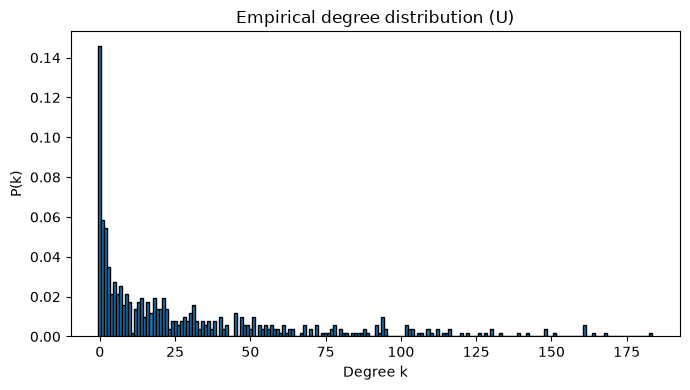

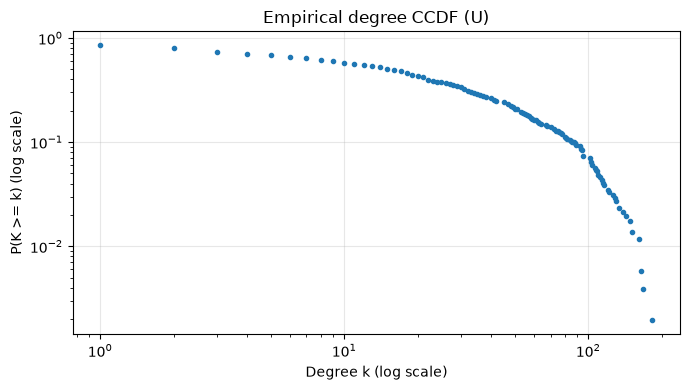

In [7]:
# Plot degree distribution for undirected graph U
degrees_U = np.array([d for _, d in U.degree()])

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(-0.5, degrees_U.max() + 1.5, 1)  # discrete bins for integer degrees
ax.hist(degrees_U, bins=bins, density=True, edgecolor="black")
ax.set_xlabel("Degree k")
ax.set_ylabel("P(k)")
ax.set_title("Empirical degree distribution (U)")
fig.tight_layout()
fig.savefig(OUT_DIR / "degree_histogram.png", dpi=200)
plt.show()

## Compute and plot Complementary Cumulative Distribution Function (CCDF)
def ccdf(values):
    values = np.asarray(values)
    k, counts = np.unique(values[values > 0], return_counts=True)
    p = counts[::-1].cumsum()[::-1] / len(values)
    return k, p

## Compute empirical (k, P(K >= k)) data points for degree values
k_emp, p_emp = ccdf(degrees_U)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(k_emp, p_emp, marker=".", linestyle="none")
ax.set_xlabel("Degree k (log scale)")
ax.set_ylabel("P(K >= k) (log scale)")
ax.set_title("Empirical degree CCDF (U)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "degree_ccdf_empirical.png", dpi=200)
plt.show()

In [20]:
print("max degree on U:", max(d for _, d in U.degree()))

max degree on U: 183


### 7. Model network benchmarking
* Here we compare our empirical network $U$ against three canonical theoretical graph models (Erdős–Rényi, Watts–Strogatz, and Barabási–Albert)

ER p = 0.0565 | WS k = 28, p = 0.1 | BA m = 14


Models: 100%|██████████| 3/3 [00:31<00:00, 10.59s/model]


,N,M,<k>,<C>,<L> (LCC),r,LCC share
Empirical (U),514,"7,449",28.9844,0.3515,2.3717,-0.0981,0.8541
"ER (mean ± std, 20 runs)",514,"7,403.6 ± 51.6",28.8078 ± 0.2006,0.0561 ± 0.0009,2.1306 ± 0.0047,-0.0020 ± 0.0098,1.0000 ± 0.0000
"WS (mean ± std, 20 runs)",514,"7,196.0 ± 0.0",28.0000 ± 0.0000,0.5346 ± 0.0043,2.6070 ± 0.0068,-0.0054 ± 0.0109,1.0000 ± 0.0000
"BA (mean ± std, 20 runs)",514,"7,000.0 ± 0.0",27.2374 ± 0.0000,0.1199 ± 0.0035,2.1650 ± 0.0047,-0.0305 ± 0.0089,1.0000 ± 0.0000


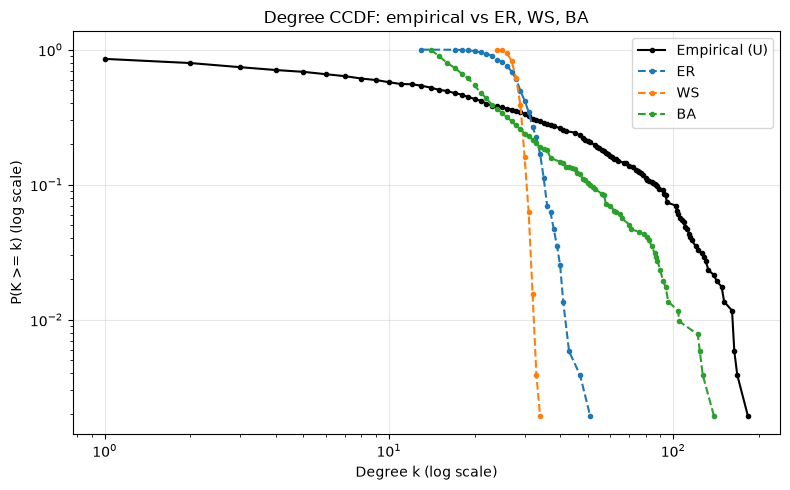

In [18]:
# Model parameters
N_emp = emp["N"]
avg_k_emp = emp["avg_k"]
#Erdős–Rényi (ER)
P_ER = avg_k_emp / (N_emp - 1)
# Watts–Strogatz (WS)
K_WS = int(round(avg_k_emp / 2)) * 2
WS_REWIRE = 0.1
# Barabási–Albert (BA)
M_BA = max(1, int(round(avg_k_emp / 2)))
#Number of repetitions for each model
N_REPS = 20
MODEL_NAMES = ["ER", "WS", "BA"]

print(f"ER p = {P_ER:.4f} | WS k = {K_WS}, p = {WS_REWIRE} | BA m = {M_BA}")

# Use the CCDF function defined in Section 6
k_emp, p_emp = ccdf(degrees_U)

#Generate one realisation of each model for comparison with empirical data
def make_model(name, seed):
    if name == "ER":
        return nx.erdos_renyi_graph(N_emp, P_ER, seed=seed)
    if name == "WS":
        return nx.watts_strogatz_graph(N_emp, K_WS, WS_REWIRE, seed=seed)
    if name == "BA":
        return nx.barabasi_albert_graph(N_emp, M_BA, seed=seed)
    raise ValueError(name)

#Generate multiple realisations of each model and compute their summary statistics
records = []
for name in tqdm(MODEL_NAMES, desc="Models", unit="model"):
    for rep in range(N_REPS):
        g = make_model(name, seed=SEED + rep)
        records.append({"model": name, **graph_summary(g)})

models_df = pd.DataFrame(records)
models_df.to_csv(OUT_DIR / "model_realisations.csv", index=False)

# Compare summary statistics across models

rows = {
    "Empirical (U)": {
        "N": str(emp["N"]),
        "M": f'{emp["M"]:,}',
        "<k>": f'{emp["avg_k"]:.4f}',
        "<C>": f'{emp["C_avg"]:.4f}',
        "<L> (LCC)": f'{emp["L_LCC"]:.4f}',
        "r": f'{emp["r_degree"]:.4f}',
        "LCC share": f'{emp["LCC_share"]:.4f}'
    }
}

for name in MODEL_NAMES:
    sub = models_df[models_df["model"] == name]

    rows[f"{name} (mean ± std, {N_REPS} runs)"] = {
        "N": str(int(sub["N"].iloc[0])),
        "M": f'{sub["M"].mean():,.1f} ± {sub["M"].std(ddof=1):,.1f}',
        "<k>": f'{sub["avg_k"].mean():.4f} ± {sub["avg_k"].std(ddof=1):.4f}',
        "<C>": f'{sub["C_avg"].mean():.4f} ± {sub["C_avg"].std(ddof=1):.4f}',
        "<L> (LCC)": f'{sub["L_LCC"].mean():.4f} ± {sub["L_LCC"].std(ddof=1):.4f}',
        "r": f'{sub["r_degree"].mean():.4f} ± {sub["r_degree"].std(ddof=1):.4f}',
        "LCC share": f'{sub["LCC_share"].mean():.4f} ± {sub["LCC_share"].std(ddof=1):.4f}'
    }

comparison = pd.DataFrame.from_dict(rows, orient="index")

display(comparison)

comparison.to_csv(OUT_DIR / "model_comparison.csv")

# Degree CCDF overlay: empirical vs one realisation of each model
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(k_emp, p_emp, "k-o", markersize=3, label="Empirical (U)")
for name in MODEL_NAMES:
    g = make_model(name, seed=SEED)
    k_m, p_m = ccdf([d for _, d in g.degree()])
    ax.loglog(k_m, p_m, linestyle="--", marker=".", label=name)
ax.set_xlabel("Degree k (log scale)")
ax.set_ylabel("P(K >= k) (log scale)")
ax.set_title("Degree CCDF: empirical vs ER, WS, BA")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "degree_ccdf_vs_models.png", dpi=200)
plt.show()

### 8. Centrality and influential nodes
* Here we calculate degree, betweenness, closeness, and weighted pagerank on directed graph $G$ to rank influential channels, analyze metric correlations, identify structural bridge channels, and evaluate group representation among top nodes

In [11]:
cent = pd.DataFrame({
    "group": {n: G.nodes[n]["group"] for n in G.nodes},
    # in_degree: how many different channels mentioned this channel
    "in_degree": dict(G.in_degree()),
    # out_degree: how many different channels this channel mentioned
    "out_degree": dict(G.out_degree()),
    # total_degree: in_degree + out_degree (all links together)
    "total_degree": dict(G.degree()),

    #DEGREE CENTRALITY (how many channels is this one directly linked to?)
    "degree_centrality": nx.degree_centrality(G),

    #BETWEENNESS CENTRALITY (share of shortest paths between all pairs of channels that pass through this node)
    "betweenness": nx.betweenness_centrality(G, normalized=True),

    #CLOSENESS CENTRALITY (how quickly this channel can be reached from all the others)
    "closeness_in": nx.closeness_centrality(G),

    #PAGERANK (importance that accounts for who links to the channel)
    "pagerank_weighted": nx.pagerank(G, weight="weight"),
})

cent.index.name = "username"
cent.to_csv(OUT_DIR / "centrality_all_nodes.csv")

# The list of measures we work with below.
CENT_MEASURES = [
    "degree_centrality",
    "betweenness",
    "closeness_in",
    "pagerank_weighted"
]

def top_k(df, measure, k=10):
    out = df.sort_values(measure, ascending=False).head(k)

    columns = ["group", measure]

    if measure == "degree_centrality":
        columns.append("total_degree")

    return out[columns].reset_index()

# One table per measure
for measure in CENT_MEASURES:
    print(f"\nTop 10 by {measure}")
    display(top_k(cent, measure))

# Spearman correlation shows whether two measures rank the nodes in a similar order.
print("\nSpearman correlation between measures:")
display(cent[CENT_MEASURES].corr(method="spearman").round(3))

top_sets = {m: set(top_k(cent, m)["username"]) for m in CENT_MEASURES}

overlap_rows = [
    {"measure_a": a, "measure_b": b, "shared_in_top10": len(top_sets[a] & top_sets[b])}
    for i, a in enumerate(CENT_MEASURES)
    for b in CENT_MEASURES[i + 1:]   
]
print("\nTop-10 overlap between measures:")
display(pd.DataFrame(overlap_rows))

group_share = pd.DataFrame({
    m: cent.sort_values(m, ascending=False).head(10)["group"].value_counts(normalize=True)
    for m in CENT_MEASURES
}).fillna(0)

# Baseline: the share of each group among all channels.
group_share["all_nodes (baseline)"] = channels["group"].value_counts(normalize=True)

print("Share of each group in the top 10 (and in the whole network):")
display(group_share.round(3))

print(f"Nodes with betweenness above zero: {(cent['betweenness'] > 0).sum()} of {len(cent)}")

# Top 20 by betweenness minus top 20 by degree: channels missing from the degree top list.
top20_bc = set(cent.sort_values("betweenness", ascending=False).head(20).index)
top20_deg = set(cent.sort_values("total_degree", ascending=False).head(20).index)
bridge_candidates = cent.loc[sorted(top20_bc - top20_deg)]

print("\nTop 20 by betweenness but not in the top 20 by degree (bridge candidates):")
if bridge_candidates.empty:
    print("None: the top-20 sets by betweenness and by degree are the same.")
else:
    display(bridge_candidates[["group", "total_degree", "betweenness"]]
            .sort_values("betweenness", ascending=False))

top_tables = pd.concat(
    {m: top_k(cent, m).assign(measure=m) for m in CENT_MEASURES},
    ignore_index=True,
)
top_tables.to_csv(OUT_DIR / "top10_centrality.csv", index=False)
print("\nTop-10 table saved: top10_centrality.csv")


Top 10 by degree_centrality


,username,group,degree_centrality,total_degree
0,rus_demiurge,Pro-Kremlin,0.454191,233
1,dr_alex_sosnowski,Pro-Kremlin,0.428850,220
2,sashakots,Pro-Kremlin,0.426901,219
3,solovievlive,Pro-Kremlin,0.426901,219
4,sergeykolyasnikov,Pro-Kremlin,0.405458,208
5,t34newsfeed,Pro-Kremlin,0.387914,199
6,boris_rozhin,Pro-Kremlin,0.385965,198
7,karaulny,Pro-Kremlin,0.362573,186
8,russica2,Pro-Kremlin,0.362573,186
9,rybar,Pro-Kremlin,0.339181,174



Top 10 by betweenness


,username,group,betweenness
0,russica2,Pro-Kremlin,0.040485
1,sashakots,Pro-Kremlin,0.032013
2,solovievlive,Pro-Kremlin,0.031330
3,karaulny,Pro-Kremlin,0.027250
4,kaktovottak,Pro-Kremlin,0.027191
5,rus_demiurge,Pro-Kremlin,0.027001
6,t34newsfeed,Pro-Kremlin,0.025523
7,sergeykolyasnikov,Pro-Kremlin,0.025355
8,boris_rozhin,Pro-Kremlin,0.023261
9,dr_alex_sosnowski,Pro-Kremlin,0.019898



Top 10 by closeness_in


,username,group,closeness_in
0,rybar,Pro-Kremlin,0.362812
1,sashakots,Pro-Kremlin,0.359039
2,opersvodki,Pro-Kremlin,0.342423
3,bbbreaking,Pro-Kremlin,0.340447
4,boris_rozhin,Pro-Kremlin,0.334138
5,readovkanews,Pro-Kremlin,0.333600
6,dimsmirnov175,Pro-Kremlin,0.332529
7,voenkorkotenok,Pro-Kremlin,0.329357
8,mig41,Pro-Kremlin,0.328313
9,solovievlive,Pro-Kremlin,0.326245


... (7 outputs left out)

,degree_centrality,betweenness,closeness_in,pagerank_weighted,all_nodes (baseline)
group,,,,,
Anti-Kremlin,0.0,0.0,0.0,0.2,0.222
Pro-Kremlin,1.0,1.0,1.0,0.8,0.778


Nodes with betweenness above zero: 315 of 514

Top 20 by betweenness but not in the top 20 by degree (bridge candidates):


,group,total_degree,betweenness
username,,,
kaktovottak,Pro-Kremlin,133,0.027191
vchkogpu,Anti-Kremlin,101,0.017614
madam_secretar,Pro-Kremlin,141,0.014767
rusbrief,Pro-Kremlin,115,0.014227
metametrica,Pro-Kremlin,113,0.013736
politjoystic,Pro-Kremlin,130,0.013567
obrazbuduschego2,Pro-Kremlin,131,0.012622
eshkinkrot,Anti-Kremlin,43,0.012474



Top-10 table saved: top10_centrality.csv


### 9. Robustness and targeted attacks

This analysis compares random node removal (20 runs), static targeted removal based on initial degree and betweenness, and adaptive removal based on the currently highest-degree node to evaluate the structural robustness of the network.

Random removal: 100%|██████████| 20/20 [00:07<00:00,  2.56run/s]


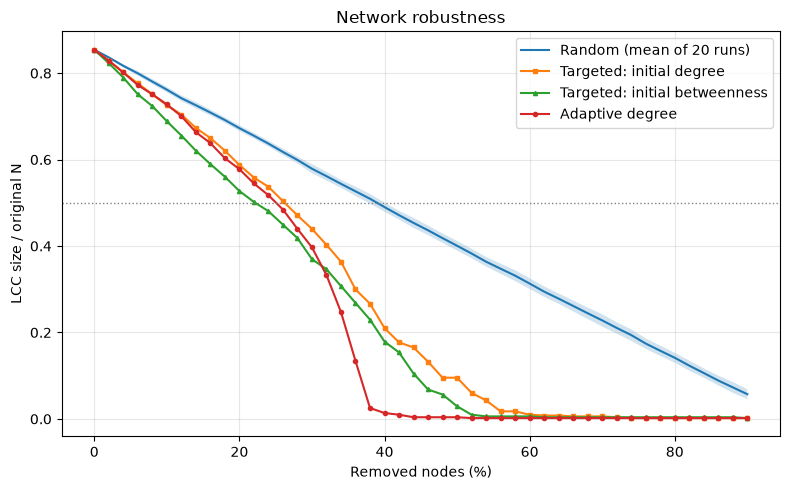

,Removal threshold (%)
Random (mean of 20 runs),40.0
Targeted: initial degree,28.0
Targeted: initial betweenness,24.0
Adaptive degree,26.0


Duplicate rows: 0


In [24]:
# The y-axis is LCC size divided by the original N
FRACS = np.round(np.arange(0, 0.901, 0.02), 2)
nodes_U = list(U.nodes())


def lcc_size(g):
    if g.number_of_nodes() == 0:
        return 0
    return len(max(nx.connected_components(g), key=len))


def curve_from_order(order):
    out = []
    for f in FRACS:
        k = int(round(f * N_emp))
        H = U.copy()
        H.remove_nodes_from(order[:k])
        out.append(lcc_size(H) / N_emp)
    return np.array(out)

# Adaptive degree attack: remove the currently highest-degree node at each step
def adaptive_degree_curve():
    H = U.copy()
    removed = 0
    out = []
    for f in FRACS:
        target = int(round(f * N_emp))
        while removed < target and H.number_of_nodes() > 0:
            node = max(H.degree, key=lambda x: x[1])[0]
            H.remove_node(node)
            removed += 1
        out.append(lcc_size(H) / N_emp)
    return np.array(out)


# 1. Random failures (mean and std over runs)
robustness_rng = np.random.default_rng(SEED)
random_curves = np.array([
    curve_from_order([nodes_U[i] for i in robustness_rng.permutation(N_emp)])
    for _ in tqdm(range(N_REPS), desc="Random removal", unit="run")
])
random_mean = random_curves.mean(axis=0)
random_std = random_curves.std(axis=0, ddof=1)

# 2. Static degree attack
deg_order = sorted(nodes_U, key=lambda n: U.degree(n), reverse=True)
deg_curve = curve_from_order(deg_order)

# 3. Static betweenness attack (on U)
bc_U = nx.betweenness_centrality(U, normalized=True)
bc_order = sorted(nodes_U, key=lambda n: bc_U[n], reverse=True)
bc_curve = curve_from_order(bc_order)

# 4. Adaptive degree attack
adaptive_curve = adaptive_degree_curve()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(FRACS * 100, random_mean, label=f"Random (mean of {N_REPS} runs)")
ax.fill_between(FRACS * 100, random_mean - random_std, random_mean + random_std, alpha=0.2)
ax.plot(FRACS * 100, deg_curve, marker="s", markersize=3, label="Targeted: initial degree")
ax.plot(FRACS * 100, bc_curve, marker="^", markersize=3, label="Targeted: initial betweenness")
ax.plot(FRACS * 100, adaptive_curve, marker="o", markersize=3, label="Adaptive degree")
ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("Removed nodes (%)")
ax.set_ylabel("LCC size / original N")
ax.set_title("Network robustness")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "robustness.png", dpi=200)
plt.show()


def threshold_point(curve, level=0.5):
    """First removal fraction at which the LCC share drops below `level`."""
    below = np.where(curve < level)[0]
    return float(FRACS[below[0]]) if below.size else None

robustness_summary = pd.DataFrame.from_dict(
    {
        "Random (mean of 20 runs)": 100 * threshold_point(random_mean),
        "Targeted: initial degree": 100 * threshold_point(deg_curve),
        "Targeted: initial betweenness": 100 * threshold_point(bc_curve),
        "Adaptive degree": 100 * threshold_point(adaptive_curve),
    },
    orient="index",
    columns=["Removal threshold (%)"]
)

display(robustness_summary)

print("Duplicate rows:", robustness_summary.index.duplicated().sum())
robustness_summary.to_csv(
    OUT_DIR / "robustness_thresholds.csv"
)

### 10. Export file for visualisation

In [23]:
import pandas as pd
from pathlib import Path

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

deg = dict(U.degree())

# Nodes: all 514 channels
nodes = pd.DataFrame({
    "id": list(U.nodes()),
    "label": ["@" + n for n in U.nodes()],
    "group": [U.nodes[n]["group"] for n in U.nodes()],
    "degree": [deg[n] for n in U.nodes()],
})
nodes.to_csv(OUT_DIR / "cosmograph_nodes.csv", index=False)

# Edges: one row per directed mention, with weight
edges = pd.DataFrame(
    [(s, t, w) for s, t, w in G.edges(data="weight")],
    columns=["source", "target", "weight"],
)
edges.to_csv(OUT_DIR / "cosmograph_edges.csv", index=False)

print(f"nodes: {len(nodes)}, edges: {len(edges)}")
print("Saved:", (OUT_DIR / "cosmograph_nodes.csv").resolve())
print("Saved:", (OUT_DIR / "cosmograph_edges.csv").resolve())

nodes: 514, edges: 8581
Saved: /Users/cutiegirl/Downloads/Assignment1_Volkova_16897137/outputs/cosmograph_nodes.csv
Saved: /Users/cutiegirl/Downloads/Assignment1_Volkova_16897137/outputs/cosmograph_edges.csv
